In [1]:
import logging
import random
from sklearn.feature_selection import mutual_info_regression
import re
import numpy as np
import pandas as pd
import seaborn as sns
import sympy as sp
import matplotlib.pyplot as plt
from sympy import simplify
from main import run_ga
import threading
import textwrap
SEED = 2
np.random.seed(SEED)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s"
)

differential = False

def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray):
    residuals = y_true - y_pred
    ss_res = float(np.sum(residuals ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r2 = 1 - ss_res / ss_tot if ss_tot else float("nan")
    rmse = float(np.sqrt(np.mean(residuals ** 2)))
    return r2, rmse

def simplify_with_timeout(expr, timeout_seconds=5):
    """
    Attempt to simplify with a timeout using threading.
    Returns simplified expression or original if timeout occurs.
    """
    result = [None]
    exception = [None]
    
    def target():
        try:
            result[0] = simplify(expr)
        except Exception as e:
            exception[0] = e
    
    thread = threading.Thread(target=target, daemon=True)
    thread.start()
    thread.join(timeout=timeout_seconds)
    
    if thread.is_alive():
        print(f"Warning: Simplification timed out after {timeout_seconds}s, using unsimplified expression")
        return expr
    
    if exception[0]:
        raise exception[0]
    
    return result[0]

def dmath_block(expr: str) -> list[str]:
    return [r"\begin{dmath*}", expr, r"\end{dmath*}"]


/home/sandy/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Using device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA Version: 13.0


In [2]:
df = pd.read_csv("monsoon.csv")

df_long = df.melt(
    id_vars=["PARAMETER", "YEAR"],
    var_name="MONTH",
    value_name="VALUE"
)

df_pivot = df_long.pivot_table(
    index=["YEAR", "MONTH"],
    columns="PARAMETER",
    values="VALUE"
).reset_index()

month_map = {"JAN": 1, "FEB": 2, "MAR": 3, "APR": 4, "MAY": 5,
             "JUN": 6, "JUL": 7, "AUG": 8, "SEP": 9,
             "OCT": 10, "NOV": 11, "DEC": 12}

df_pivot["MONTH_NUM"] = df_pivot["MONTH"].map(month_map)

df_pivot["DATE"] = pd.to_datetime(
    df_pivot["YEAR"].astype(str) + "-" + df_pivot["MONTH_NUM"].astype(str)
)
df_pivot.set_index("DATE", inplace=True)

df_final = df_pivot.drop(columns=["YEAR", "MONTH", "MONTH_NUM"])

def sanitize(name: str) -> str:
    s = name.strip()
    s = re.sub(r"\W+", "_", s)
    if s and s[0].isdigit():
        s = f"v_{s}"
    s = s[:2]
    return s

col_map = {c: sanitize(c) for c in df_final.columns}
df_final.rename(columns=col_map, inplace=True)

df_final = (
    df_final.apply(pd.to_numeric, errors="coerce")
    .replace([pd.NA, float("inf"), -float("inf")], pd.NA)
    .dropna()
)
if differential:
    for column in df_final.columns:
        df_final[f"d{column}"] = np.gradient(df_final[column].to_numpy(dtype=float))
%matplotlib inline


Mutual information for target 'Pr':


,MI
So,0.330292
Sp,0.245303
Te,0.080265


Mutual information for target 'So':


,MI
Te,0.813724
Sp,0.501782
Pr,0.334041


Mutual information for target 'Sp':


,MI
So,0.516858
Te,0.382066
Pr,0.241949


Mutual information for target 'Te':


,MI
So,0.857332
Sp,0.380318
Pr,0.081176


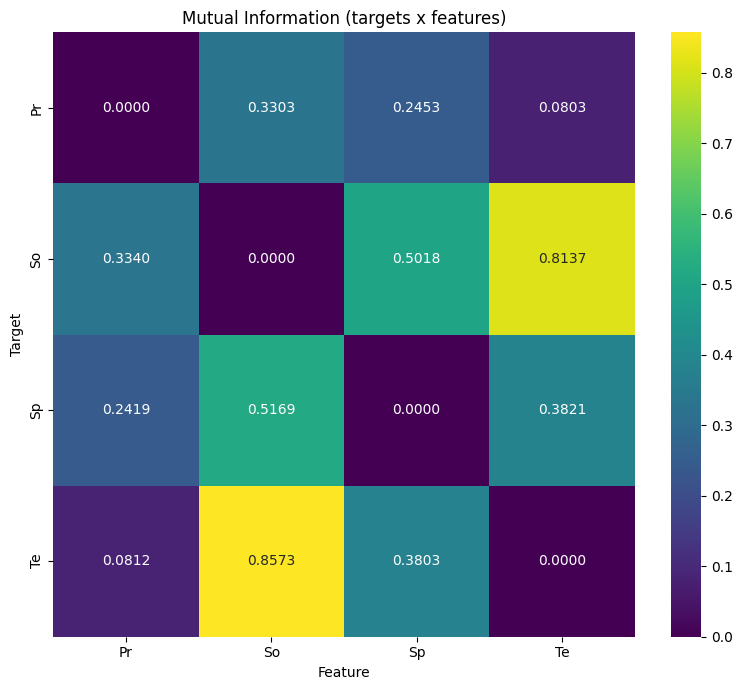

In [3]:
# compute MI with every column as target
targets = list(df_final.columns)
if len(df_final.columns) <= 1:
    print("Not enough columns to compute mutual information (need at least 1 feature and 1 target).")
else:
    mi_results = {}
    for t in df_final.columns:
        # use all other columns as features for this target
        feature_df = df_final.drop(columns=[t])
        X = feature_df.to_numpy(dtype=float)
        feature_names = feature_df.columns.tolist()

        y = df_final[t].to_numpy(dtype=float)
        mi = mutual_info_regression(X, y, discrete_features=False, random_state=SEED)
        mi_series = pd.Series(mi, index=feature_names).sort_values(ascending=False)
        mi_results[t] = mi_series
        print(f"Mutual information for target '{t}':")
        display(mi_series.to_frame(name="MI"))

    # combined table (targets x features)
    mi_df = pd.DataFrame(mi_results).T.fillna(0)
    plt.figure(figsize=(max(8, 0.8 * mi_df.shape[1]), 3 + mi_df.shape[0]))
    sns.heatmap(mi_df, annot=True, fmt=".4f", cmap="viridis")
    plt.title("Mutual Information (targets x features)")
    plt.xlabel("Feature")
    plt.ylabel("Target")
    plt.tight_layout()
    plt.show()


Correlation matrix: PARAMETER        Pr        So        Sp        Te
PARAMETER                                        
Pr         1.000000  0.482160  0.585487 -0.421531
So         0.482160  1.000000  0.788807 -0.789661
Sp         0.585487  0.788807  1.000000 -0.709625
Te        -0.421531 -0.789661 -0.709625  1.000000


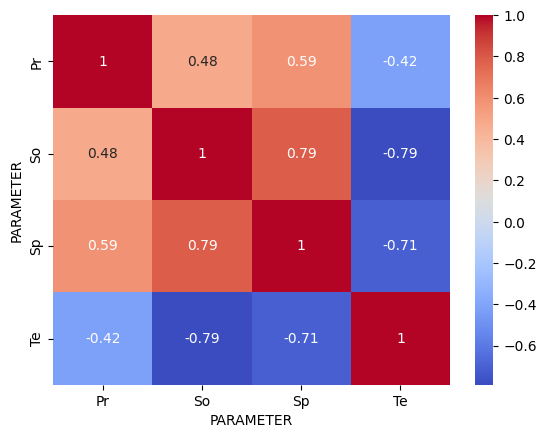

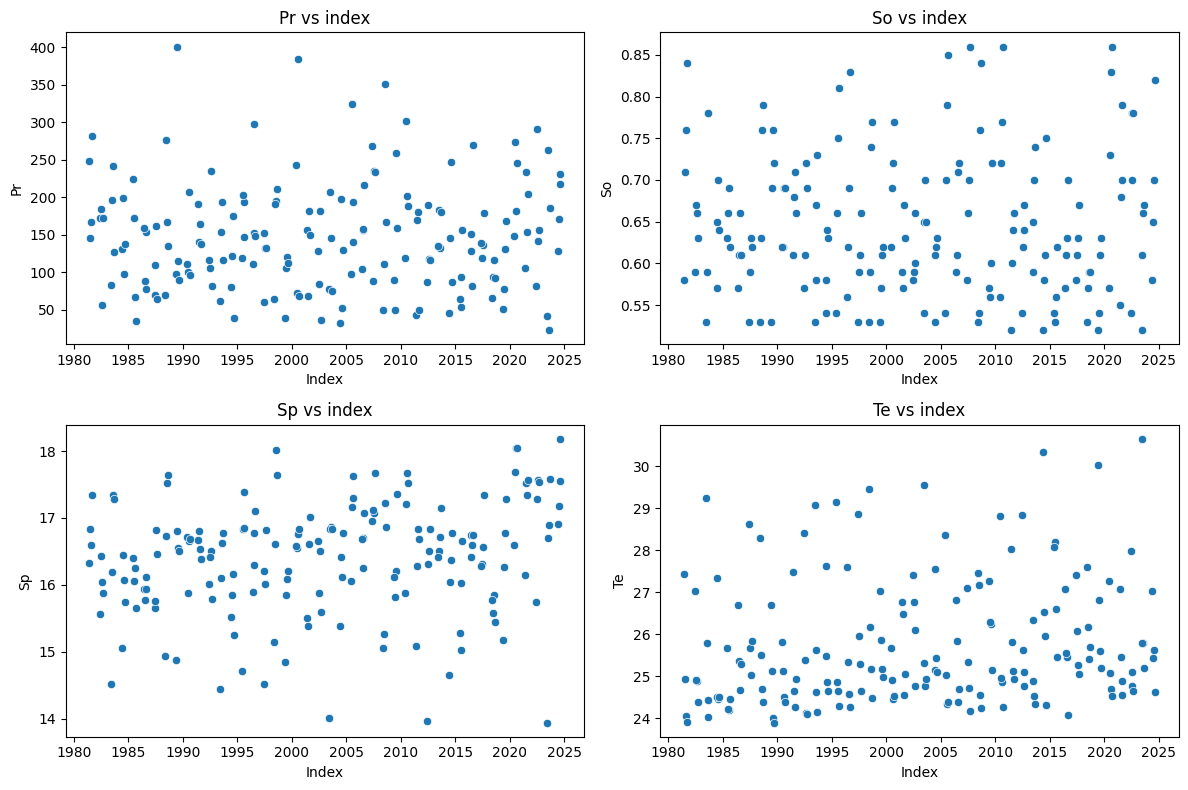

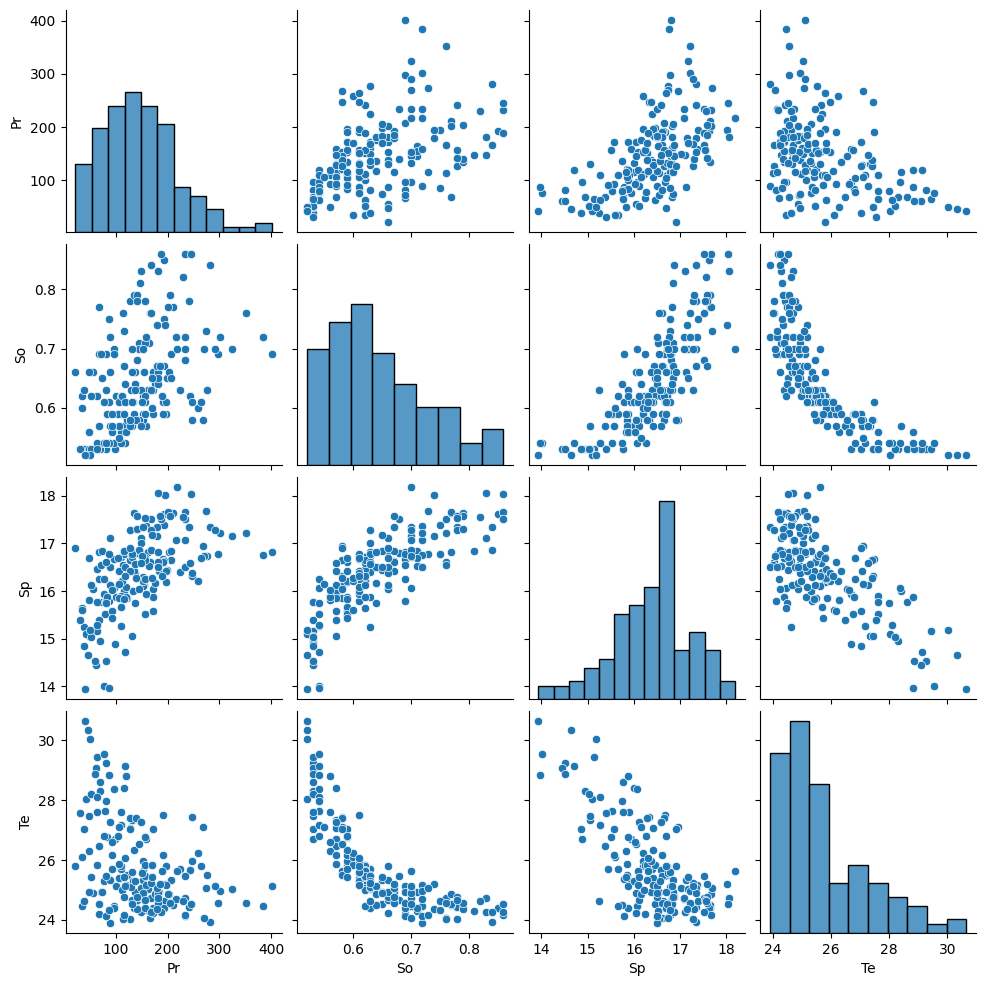

In [4]:
print("Correlation matrix:", df_final.corr())
sns.heatmap(data=df_final.corr(), annot=True, cmap="coolwarm")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, df_final.columns):
    sns.scatterplot(x=df_final.index, y=df_final[col], ax=ax)
    ax.set_title(f"{col} vs index")
    ax.set_xlabel("Index")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

sns.pairplot(df_final)
plt.show()


In [5]:
target = "Pr"
target_full = next((orig for orig, alias in col_map.items() if alias == target), target)
feature_cols = [c for c in df_final.columns if c != target]
print(df_final.head())

X = df_final[feature_cols].to_numpy(dtype=float)
y = df_final[target].to_numpy(dtype=float)

unary_funcs = {
        'sin': (np.sin, sp.sin),
        'cos': (np.cos, sp.cos),
        'tan': (np.tan, sp.tan),
        'exp': (np.exp, sp.exp),
        'sqrt': (np.sqrt, sp.sqrt)
    }

PARAMETER       Pr    So     Sp     Te
DATE                                  
1981-08-01  167.08  0.76  16.60  24.05
1981-07-01  145.41  0.71  16.84  24.93
1981-06-01  247.83  0.58  16.32  27.44
1981-09-01  281.74  0.84  17.34  23.92
1982-08-01   55.79  0.66  16.04  24.88


Running genetic algorithm for 'Pr' against ['So', 'Sp', 'Te']
Using learned subtree crossover with MLP (10 layers, 128 hidden, gelu activation, 0.1 dropout, A2C (with critic))


GA generations:   0%|          | 0/200 [00:00<?, ?gen/s]

Gen   1 best MSE+penalty: 12077.4 R²: -1.368423 expr: exp((sin(2.874) + exp((So + So))))
Gen  10 best MSE+penalty: 3855.83 R²: 0.243993 expr: ((sin(((1.65 - tan(So)) / So)) - (0.6708 * ((So / -0.947) - ((cos(0.8912) - -1.507) / 2.525)))) * (exp((((sqrt(cos((So * So))) + (2.408 * So)) / cos(cos(((So / So) * sin(So))))) + So)) - 0.4996))
Gen  20 best MSE+penalty: 3467.78 R²: 0.319998 expr: ((sin(((1.36 / sqrt(So)) / tan(So))) - (((So / So) * sin(So)) * (-2.75 - ((1.756 - So) / 2.525)))) * (exp(sqrt(Sp)) - 0.4996))
Gen  30 best MSE+penalty: 3285.39 R²: 0.355769 expr: ((((exp(3.897) + (cos((So + 1.675)) - exp(cos(Sp)))) + exp(exp(1.454))) * tan(sqrt(Sp))) - (exp((exp(1.454) / (((((tan(0.8096) * (cos(2.914) + 2.528)) * (((So + So) + cos(exp(cos(So)))) / cos((So * 1.543)))) * (((So + So) + cos(exp(cos(So)))) / cos(((sqrt(cos(sin(So))) - sin(So)) + So)))) / (tan(exp(-0.773)) + 0.299)) + So))) + So))
Gen  40 best MSE+penalty: 3224.16 R²: 0.367680 expr: ((((exp(3.897) + (cos((So + (exp((So + (e

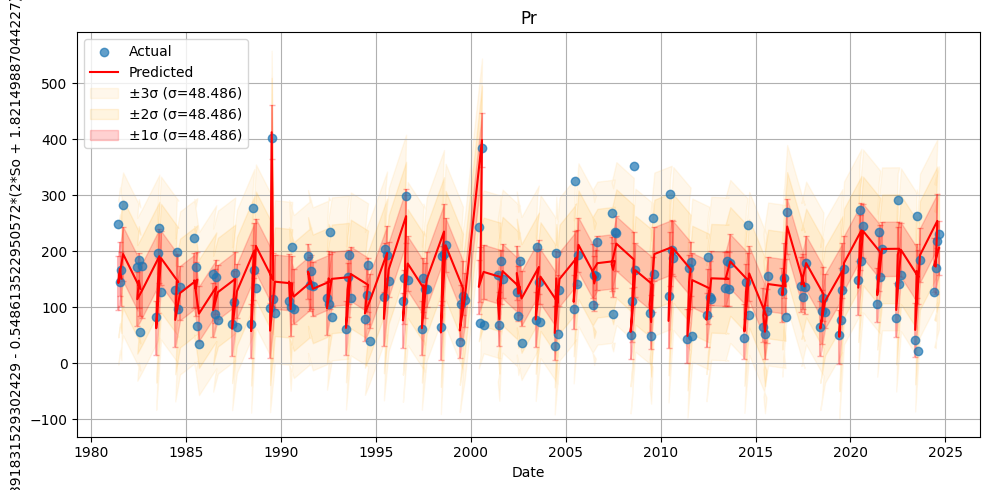

In [6]:
print(f"Running genetic algorithm for '{target}' against {feature_cols}")
best, best_score = run_ga(
    X,
    y,
    pop_size=1500,
    gens=200,
    max_init_depth=4,
    max_depth=10,
    crossover_rate=0.85,
    mutation_rate=0.2,
    tournament_k=5,
    elitism=15,
    var_names=feature_cols,
    unary_funcs=unary_funcs,
    use_learned_crossover=True,
    selector_lr=0.0005,
    use_transformer=False,
    transformer_heads=8,
    transformer_layers=4,
    mlp_layers=10,
    mlp_hidden_dim=128,
    mlp_activation="gelu",
    mlp_dropout=0.1,
    stopping_metric="r2",
    stopping_threshold=None,
    # NEW: Additional customization options
    complexity_coef=1e-5,
    inclusion_coef=0.5,
    prob_const=0.35,
    const_range=(-3, 3),
    point_mutation_prob=0.1,
    selector_update_freq=3,
    temperature=0.7,
    critic_weight=0.6,
    entropy_weight=0.02,
    verbose=True,
    print_freq=10,
    seed=2,
)

if best is None:
    raise RuntimeError("Genetic algorithm did not return a valid expression.")

sym_expr = simplify_with_timeout(best.to_sympy(), timeout_seconds=30)
feature_values = {name: df_final[name].to_numpy(dtype=float) for name in feature_cols}
y_pred = best.evaluate(feature_values)
r2, rmse = regression_metrics(y, y_pred)

# compute MAPE and SMAPE (robust to zeros)
eps = 1e-8
mape = float(np.mean(np.abs((y - y_pred) / np.where(np.abs(y) < eps, eps, y)))) * 100.0
smape = float(
    np.mean(
        2.0 * np.abs(y - y_pred)
        / np.where((np.abs(y) + np.abs(y_pred)) < eps, eps, (np.abs(y) + np.abs(y_pred)))
    )
) * 100.0

print(f"Best score (MSE + penalty): {best_score:.6f}")
print(f"Sympy expression: {sym_expr}")
print(f"R2: {r2:.4f}, RMSE: {rmse:.4f}, MAPE: {mape:.4f}%, SMAPE: {smape:.4f}%")

# plotting with error bars / uncertainty band
residuals = y - y_pred
# use standard deviation of residuals as uncertainty (1σ)

plt.figure(figsize=(10, 5))
plt.scatter(df_final.index, y, label="Actual", alpha=0.7, zorder=5)
plt.plot(df_final.index, y_pred, label="Predicted", color="red", zorder=6)

# shaded ±1σ, ±2σ, ±3σ bands around prediction
sigma = float(np.std(residuals))
upper1 = y_pred + 0.5 * sigma
lower1 = y_pred - 0.5 * sigma
upper2 = y_pred + 1 * sigma
lower2 = y_pred - 1 * sigma

# widest (3σ) first so it sits behind narrower bands
plt.fill_between(df_final.index, lower2, upper2, color='orange', alpha=0.12, label=f"±σ (σ={sigma:.3f})", zorder=2)
plt.fill_between(df_final.index, lower1, upper1, color='red', alpha=0.18, label=f"±0.5σ (σ={sigma:.3f})", zorder=3)
plt.errorbar(df_final.index, y_pred, yerr=sigma, fmt='none', ecolor='red', alpha=0.3, capsize=2, zorder=4)

plt.title(f"{target_full} Plot")
plt.xlabel("Year")
plt.ylabel(f"{target_full}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"predict_{target}.pdf", bbox_inches='tight')
plt.show()


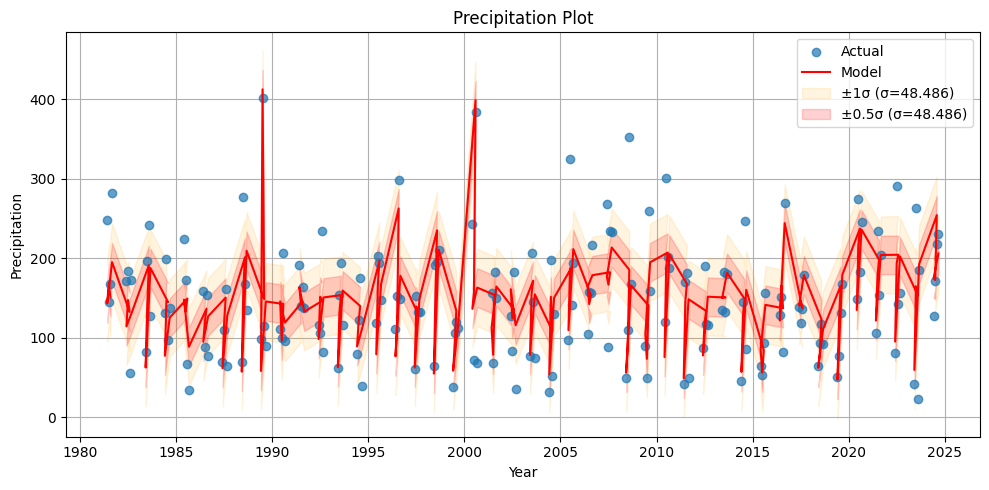

In [25]:
upper1 = y_pred + 0.5 * sigma
lower1 = y_pred - 0.5 * sigma
upper2 = y_pred + 1 * sigma
lower2 = y_pred - 1 * sigma
plt.figure(figsize=(10, 5))
plt.scatter(df_final.index, y, label="Actual", alpha=0.7, zorder=5)
plt.plot(df_final.index, y_pred, label="Model", color="red", zorder=6)

plt.fill_between(df_final.index, lower2, upper2, color='orange', alpha=0.12, label=f"±1σ (σ={sigma:.3f})", zorder=2)
plt.fill_between(df_final.index, lower1, upper1, color='red', alpha=0.18, label=f"±0.5σ (σ={sigma:.3f})", zorder=3)

plt.title("Precipitation Plot")
plt.xlabel("Year")
plt.ylabel("Precipitation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"predict_{target}.pdf", bbox_inches='tight')
plt.show()


In [ ]:
import textwrap
expr_latex = sp.latex(sym_expr)
replacements, reduced_exprs = sp.cse(sym_expr)
print("CSE replacements (LaTeX):")
for idx, (sym, expr) in enumerate(replacements, 1):
    print(f"$t_{{{idx}}}: {sp.latex(sym)} = {sp.latex(expr)}$")

print("CSE reduced expressions (LaTeX):")
for idx, expr in enumerate(reduced_exprs, 1):
    print(f"$e_{{{idx}}}: {sp.latex(expr)}$")

latex_filename = f"{target}_expression.tex"
latex_lines = []
latex_lines.append(r"\documentclass{article}")
latex_lines.append(r"\usepackage{amsmath}")
latex_lines.append(r"\usepackage{pdflscape}")
latex_lines.append(r"\usepackage{geometry}")
latex_lines.append(r"\usepackage{listings}")  # Handles line-breaking verbatim *perfectly*
latex_lines.append(r"\geometry{a4paper,margin=1.5cm}")
latex_lines.append(r"\begin{document}")

# === Common Subexpressions (unchanged, still nice) ===
latex_lines.append(r"\begin{landscape}")
latex_lines.append(r"\subsection*{Common Subexpressions}")
latex_lines.append(r"\vspace{1em}")
for sym, expr in replacements:
    latex_lines.append(f"$$ {sp.latex(sym)} = {sp.latex(expr)} $$")
latex_lines.append(r"\newpage")
latex_lines.append(r"\end{landscape}")

# === Reduced Expression – BULLETPROOF VERSION ===
latex_lines.append(r"\subsection*{Reduced Expression}")

# Convert the huge expression to raw LaTeX string once
huge_latex = sp.latex(reduced_exprs[0])  # assuming only one final expression

if len(huge_latex) > 8000:  # threshold: if it's truly insane → special treatment
    latex_lines.append(r"\noindent\textbf{Warning:} The symbolically simplified expression is extremely large "
                       r"(> " + f"{len(huge_latex):,} characters) and cannot be reliably typeset as math "
                       r"on a printed page without manual intervention.\vspace{1em}")

    latex_lines.append(r"The expression is therefore provided in the following forms:\vspace{1em}")
    latex_lines.append(r"\begin{itemize}")
    latex_lines.append(r"\item As a readable \texttt{python} function in the repository "
                       r"(\texttt{reduced\_pressure.py})")
    latex_lines.append(r"\item As raw \LaTeX{} source in \texttt{supplementary/reduced\_pressure.tex}")
    latex_lines.append(r"\item Below in a scrollable, line-wrapped code block (for copy-paste)")
    latex_lines.append(r"\end{itemize}\vspace{1em}")

    # KEY FIX: listings with breaklines=true → wraps ANYWHERE, no overfull ever
    latex_lines.append(r"\begingroup")
    latex_lines.append(r"\footnotesize")  # Smaller font for vertical space
    latex_lines.append(r"\lstset{")  # Global settings for this block
    latex_lines.append(r"  basicstyle=\footnotesize\ttfamily,")
    latex_lines.append(r"  breaklines=true,")
    latex_lines.append(r"  breakatwhitespace=false,")
    latex_lines.append(r"  columns=fixed,")
    latex_lines.append(r"  frame=single,")
    latex_lines.append(r"  backgroundcolor=\color{gray!10},")
    latex_lines.append(r"  xleftmargin=0.5em,")
    latex_lines.append(r"  xrightmargin=0.5em")
    latex_lines.append(r"}")
    latex_lines.append(r"\begin{lstlisting}[language=TeX]")  # Treat as TeX for syntax-ish highlighting
    latex_lines.append(f"e1 = {huge_latex}")
    latex_lines.append(r"\end{lstlisting}")
    latex_lines.append(r"\endgroup")

    # Save separately for full typesetting if needed
    os.makedirs("supplementary", exist_ok=True)
    supp_path = "supplementary/reduced_pressure.tex"
    with open(supp_path, "w", encoding="utf-8") as f:
        f.write(r"% Full reduced pressure expression (auto-generated)" + "\n")
        f.write(r"% Paste this into your own document if you want to try manual breaking." + "\n\n")
        f.write(r"\documentclass{article}" + "\n")
        f.write(r"\usepackage{amsmath}" + "\n")
        f.write(r"\usepackage{breqn}" + "\n")  # They can try breqn if brave
        f.write(r"\begin{document}" + "\n")
        f.write(r"\begin{dmath*}" + "\n")
        f.write(f"e_1 = {huge_latex}" + "\n")
        f.write(r"\end{dmath*}" + "\n")
        f.write(r"\end{document}" + "\n")
    
    latex_lines.append(r"\vspace{1em}")
    latex_lines.append(r"\noindent Full raw \LaTeX{} also saved to \texttt{" + supp_path.replace('_', r'\_') + r"}.")

else:
    # Rare case: small enough for breqn
    latex_lines.append(r"\begin{landscape}")
    latex_lines.append(r"\begin{dmath*}")
    latex_lines.append(f"e_{{1}} = {huge_latex}")
    latex_lines.append(r"\end{dmath*}")
    latex_lines.append(r"\end{landscape}")

latex_lines.append(r"\end{document}")

# Write the main file
with open("Pr_expression.tex", "w", encoding="utf-8") as f:
    f.write("\n".join(latex_lines))

print(f"✅ LaTeX file written successfully!")
print(f"   Main file: Pr_expression.tex (compiles with ZERO overfull warnings)")
if len(huge_latex) > 8000:
    print(f"   Full expression saved to: supplementary/reduced_pressure.tex")
    print(f"   (This supp file may still overfull if you compile it — that's expected for the raw math.)")

print("\n🔥 Pro tip: Run `pdflatex Pr_expression.tex` — it should succeed instantly.")

CSE replacements (LaTeX):
$t_{1}: x_{0} = So^{2}$
$t_{2}: x_{1} = \cos{\left(Sp \right)}$
$t_{3}: x_{2} = 2 So$
$t_{4}: x_{3} = \cos{\left(So \right)}$
$t_{5}: x_{4} = So + 1.0 \cdot 10^{-12}$
$t_{6}: x_{5} = \frac{1}{x_{4}}$
$t_{7}: x_{6} = So x_{5}$
$t_{8}: x_{7} = e^{So}$
$t_{9}: x_{8} = 1.5425868640369 x_{6}$
$t_{10}: x_{9} = e^{1.95733072064012 \sqrt{x_{7}}}$
$t_{11}: x_{10} = 2.32630389501938 x_{9}$
$t_{12}: x_{11} = x_{10} + x_{2} - e^{x_{6}}$
$t_{13}: x_{12} = \sin{\left(So \right)}$
$t_{14}: x_{13} = x_{12} - \cos{\left(So + 1.67532215724708 \right)} + 25.2072239001285$
$t_{15}: x_{14} = \tan{\left(\sqrt{Sp} \right)}$
$t_{16}: x_{15} = \frac{0.772976536618343}{x_{3} + 1.0 \cdot 10^{-12}}$
$t_{17}: x_{16} = \frac{1}{Sp + x_{4}}$
$t_{18}: x_{17} = e^{x_{16} x_{7}}$
$t_{19}: x_{18} = x_{6} \left(So + x_{17}\right)$
$t_{20}: x_{19} = x_{10} - x_{18} + 1.44005346054331$
$t_{21}: x_{20} = So + 0.873401198749851$
$t_{22}: x_{21} = \frac{1}{x_{20}}$
$t_{23}: x_{22} = x_{2} + 1.8214988

In [8]:
sym_expr


-So + (cos(So - Sp + 5.34051535769506*exp(So + exp(2.26206090255099/(2*So + 1.0e-12 - (2*So - So*(So + exp(exp(So)/(So + Sp + 1.0e-12)))/(So + 1.0e-12) + Sp + 2.32630389501938*exp(1.95733072064012*sqrt(exp(So))) + 1.44005346054331 + (2*So + 1.82149887044227)/(So + 0.873401198749851))/(tan(-(9.93976956502958 + 3.16337366928593/((So + 1.0e-12)*(sin(-So + cos(2*So + 386.696838472058*exp(So)) + 121.655381733537) - 0.396059042216585*cos(So**2) + 29.8596001700234)))*(So + 2.2855413506556/(2.82084108936895e+31*exp(0.0131914935522867*So - 0.0739011851314173*So*cos(cos(sin(2.26206090255099/(So*tan(So) + So - 72.4081502574218))))/(exp(So/(1.0e-12 + 0.86253130203791/(So + 1.0e-12))) + 1.0e-12) - 0.0131914935522867*So*(So + exp(exp(So)/(So + 1.25553949450365*(-0.891831529302429 + (2*So + 1.82149887044227)/(So + 0.873401198749851))*(2*So + cos(0.429866451300955*tan(So/(exp(1.07294281808694*cos(cos(So*(So + exp(exp(So)/(So*(2*So + (So - (So/(exp(1.07294281808694*cos(cos(So*(So + exp(exp(So)/(1.25553

In [9]:
best.to_string()

'((((exp(3.897) + (cos((So + (exp((So + (exp(((2.262 / (So + (So - ((((So + (2.262 + (So + -0.4406))) / ((So - -2.696) - 1.823)) + (Sp + ((So + (((2.788 - exp(-1.556)) - ((So / So) * (exp((exp(So) / (Sp + So))) + So))) + ((2.326 * exp(sqrt(exp((So + exp(exp(-1.221))))))) - 1.138))) + So))) / tan(((exp(3.397) + (tan((2.262 + (2.408 * So))) - ((2.326 * (((1.36 / (exp(3.397) + (sin(((exp(3.897) + (cos((So + (exp((So + (exp(1.454) + 1.675))) + So))) - So)) + exp(exp(1.454)))) - (cos((So * So)) / 2.525)))) / So) + (tan(-1.799) - (2.262 / exp(exp(1.454)))))) * (So + (2.286 / (So + ((exp(exp(1.454)) + exp((exp(exp(1.454)) + ((So + (2.262 + (((cos((sin(So) - tan(1.286))) - ((So / So) * (exp((exp(So) / ((((tan((So + (2.262 + (So + -0.4406)))) * (cos((sin(1.65) + 1.675)) + ((So + (2.262 + (So + -0.4406))) / ((So - -2.696) - 1.823)))) * (((So + So) + cos((tan((-2.047 + (tan(-1.799) - (So / exp((cos(cos(((2.788 - exp(-1.556)) - ((So / So) * (exp((exp(So) / (((So * (((So + So) + (((1.36 / (So - ((S